In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

In [52]:
files = [
    "data/Unfallorte2020_LinRef.csv",
    "data/Unfallorte_2021_LinRef.txt",
    "data/Unfallorte2022_LinRef.csv",
    "data/Unfallorte2023_LinRef.csv",
    "data/Unfallorte2024_LinRef.csv",
    "data/Unfallorte_2025_LR_BasisDLM.csv",
]

frames = []
for f in files:
    d = pd.read_csv(f, sep=";", decimal=",")
    d = d.rename(columns={"IstStrassenzustand": "STRZUSTAND"})   # ab 2021 anders benannt
    d = d.drop(columns=["OBJECTID", "OID_", "UIDENTSTLAE", "PLST"], errors="ignore")
    frames.append(d)

df = pd.concat(frames, ignore_index=True)

/var/folders/l_/gx9nbvqs3s181hk13j3hthlw0000gp/T/ipykernel_14313/287246640.py:12: DtypeWarning: Columns (23: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f, sep=";", decimal=",")
/var/folders/l_/gx9nbvqs3s181hk13j3hthlw0000gp/T/ipykernel_14313/287246640.py:12: DtypeWarning: Columns (1: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f, sep=";", decimal=",")
/var/folders/l_/gx9nbvqs3s181hk13j3hthlw0000gp/T/ipykernel_14313/287246640.py:12: DtypeWarning: Columns (0: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f, sep=";", decimal=",")


In [53]:
print(df.shape) 
print(df.isna().sum().sum())                     
print(df["UJAHR"].value_counts().sort_index()) 
print(df.groupby("UJAHR")["ULAND"].nunique())    
print(df.groupby("UJAHR")["UMONAT"].nunique())    

(1543886, 23)
0
UJAHR
2020    237994
2021    238826
2022    256492
2023    269048
2024    268519
2025    273007
Name: count, dtype: int64
UJAHR
2020    16
2021    16
2022    16
2023    16
2024    16
2025    16
Name: ULAND, dtype: int64
UJAHR
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
Name: UMONAT, dtype: int64


In [4]:
print(df.dtypes)

ULAND            int64
UREGBEZ          int64
UKREIS           int64
UGEMEINDE        int64
UJAHR            int64
UMONAT           int64
USTUNDE          int64
UWOCHENTAG       int64
UKATEGORIE       int64
UART             int64
UTYP1            int64
ULICHTVERH       int64
IstRad           int64
IstPKW           int64
IstFuss          int64
IstKrad          int64
IstGkfz          int64
IstSonstige      int64
LINREFX        float64
LINREFY        float64
XGCSWGS84      float64
YGCSWGS84      float64
STRZUSTAND       int64
dtype: object


In [54]:
df_rad = df[df["IstRad"] == 1].copy()
print(len(df_rad))

500799


1. Zeitliche Entwicklung

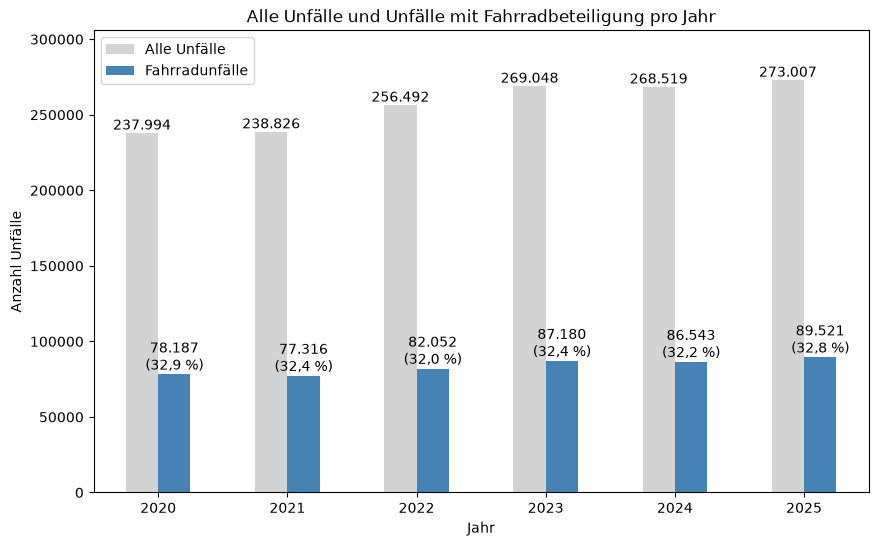

In [55]:
#  1.1 Entwicklung der Fahrradunfälle pro Jahr

alle_year = df.groupby("UJAHR").size()
rad_year = df_rad.groupby("UJAHR").size()
anteil = (rad_year / alle_year * 100).round(1)

vergleich = pd.DataFrame({
    "Alle Unfälle": alle_year,
    "Fahrradunfälle": rad_year,
})

ax = vergleich.plot(kind="bar", figsize=(10, 6), color=["lightgray", "steelblue"])


ax.bar_label(ax.containers[0], labels=[f"{v:,}".replace(",", ".") for v in alle_year])
ax.bar_label(
    ax.containers[1],
    labels=[f"{v:,}".replace(",", ".") + f"\n({str(a).replace('.', ',')} %)"
            for v, a in zip(rad_year, anteil)]
)

plt.title("Alle Unfälle und Unfälle mit Fahrradbeteiligung pro Jahr")
plt.xlabel("Jahr")
plt.ylabel("Anzahl Unfälle")
plt.xticks(rotation=0)
plt.ylim(0, alle_year.max() * 1.12)
plt.legend();

Zwischen 2020 und 2025 ist die Zahl der Unfälle mit Fahrradbeteiligung von 78.187 auf 89.521 gestiegen, das entspricht einem Plus von rund 14,5 %. Den niedrigsten Wert gab es 2021 (77.316), den höchsten 2025 (89.521). Die Entwicklung verlief nicht gleichmäßig: Auf einen leichten Rückgang 2021 (−1,1 %) folgten zwei Anstiege 2022 und 2023 (jeweils rund +6 %), danach ein minimaler Rückgang 2024 (−0,7 %) und erneut ein Anstieg 2025 (+3,4 %).

Der Anteil der Fahrradunfälle an allen Unfällen mit Personenschaden blieb in allen Jahren nahezu konstant bei 32,0 bis 32,9 %. Die Fahrradunfälle sind also nicht überproportional gewachsen, sondern im Gleichschritt mit der Gesamtzahl der Unfälle (von 237.994 auf 273.007, ebenfalls rund +15 %). Die Daten enthalten keine Angaben zur tatsächlichen Fahrradnutzung, daher lässt sich aus der Entwicklung nicht ableiten, ob Radfahren riskanter geworden ist.

UJAHR   2020   2021   2022   2023   2024   2025
UMONAT                                         
1       4274   2337   3455   3963   3293   4067
2       3642   2975   3408   3927   4055   3436
3       3670   4526   5940   4868   5617   6064
4       5932   4996   5475   5251   7042   8033
5       7500   6417  10184  10015  10163  10752
6       9204  11266   9914  12537  10194  11035
7       9598   9653   9390  10139  10560  10567
8       9141   8191   9380   9050  10487  10339
9       9978  10085   8124  11388   9063   8975
10      6460   7374   7553   7396   7066   6435
11      5237   5349   5890   5351   5349   5477
12      3551   4147   3339   3295   3654   4341
UMONAT
6    64150
7    59907
9    57613
dtype: int64


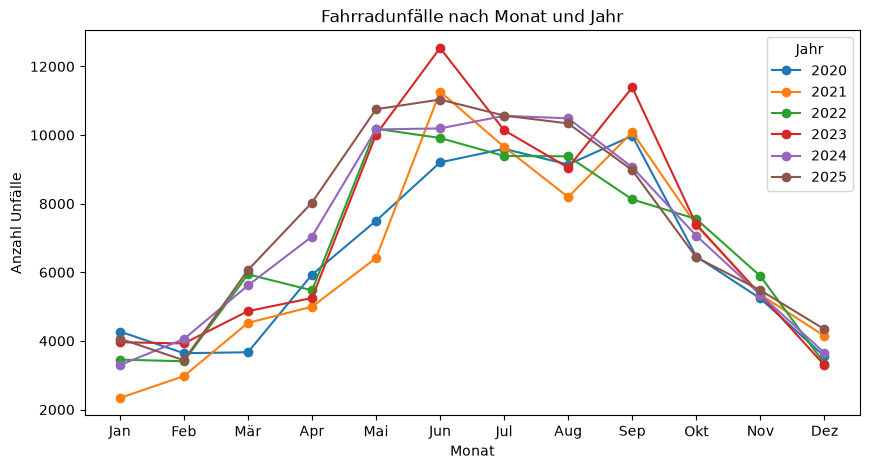

In [56]:
#  1.2 Entwicklung der Fahrradunfälle nach Monat

monate = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

rad_monat = df_rad.groupby(["UMONAT", "UJAHR"]).size().unstack()
print(rad_monat)
print(rad_monat.sum(axis=1).sort_values(ascending=False).head(3))  # Top-3-Monate


fig, ax = plt.subplots(figsize=(10, 5))
rad_monat.plot(ax=ax, marker="o")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(monate)
ax.set_title("Fahrradunfälle nach Monat und Jahr")
ax.set_xlabel("Monat")
ax.set_ylabel("Anzahl Unfälle")
ax.legend(title="Jahr");

Jan     4.3
Feb     4.3
Mär     6.1
Apr     7.3
Mai    11.0
Jun    12.8
Jul    12.0
Aug    11.3
Sep    11.5
Okt     8.4
Nov     6.5
Dez     4.5
dtype: float64
100.0


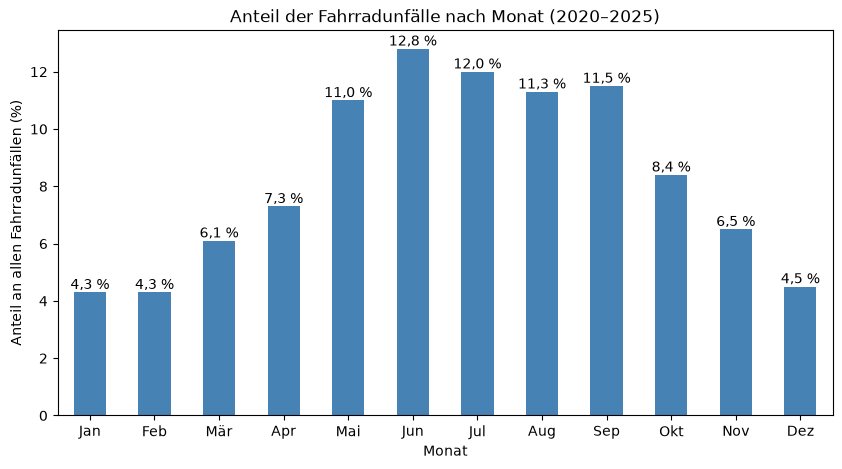

In [57]:
monat_summe = rad_monat.sum(axis=1)
anteil_monat = (monat_summe / monat_summe.sum() * 100).round(1)
anteil_monat.index = monate

print(anteil_monat)
print(anteil_monat.sum()) 

fig, ax = plt.subplots(figsize=(10, 5))
anteil_monat.plot(kind="bar", color="steelblue", ax=ax)
for i, v in enumerate(anteil_monat):
    ax.text(i, v, f"{v:.1f} %".replace(".", ","), ha="center", va="bottom")
ax.set_title("Anteil der Fahrradunfälle nach Monat (2020–2025)")
ax.set_xlabel("Monat")
ax.set_ylabel("Anteil an allen Fahrradunfällen (%)")
ax.tick_params(axis="x", rotation=0);

Fahrradunfälle zeigen eine deutliche saisonale Schwankung: Die meisten Unfälle passieren in den Sommermonaten. Über alle Jahre hinweg entfallen die meisten auf den Juni (12,8 %), gefolgt von Juli (12,0 %) und September (11,5 %). Auf die fünf Monate Mai bis September entfallen zusammen rund 59 % aller Fahrradunfälle. In den Wintermonaten Dezember bis Februar liegt der Anteil pro Monat dagegen nur bei 4,3 bis 4,5 %, zusammengenommen bei rund 13 %.

Das Muster wiederholt sich in allen Jahren, der Spitzenmonat variiert jedoch (2020: September, 2022: Mai, 2024: Juli, 2021, 2023 und 2025: Juni). Auffällig ist der Januar 2021 mit nur 2.337 Unfällen (Januar 2020: 4.274). Mögliche Ursachen wie Corona-Lockdown oder Witterung lassen sich anhand der Daten nicht belegen.

Die Häufung im Sommer zeigt, wann viele Menschen Rad fahren, nicht unbedingt, wann Radfahren am gefährlichsten ist. Daten zur tatsächlichen Fahrradnutzung liegen nicht vor.

Mo    74997
Di    81120
Mi    80839
Do    80949
Fr    77615
Sa    58520
So    46759
Name: count, dtype: int64
USTUNDE
16    47107
15    45561
17    43846
Name: count, dtype: int64


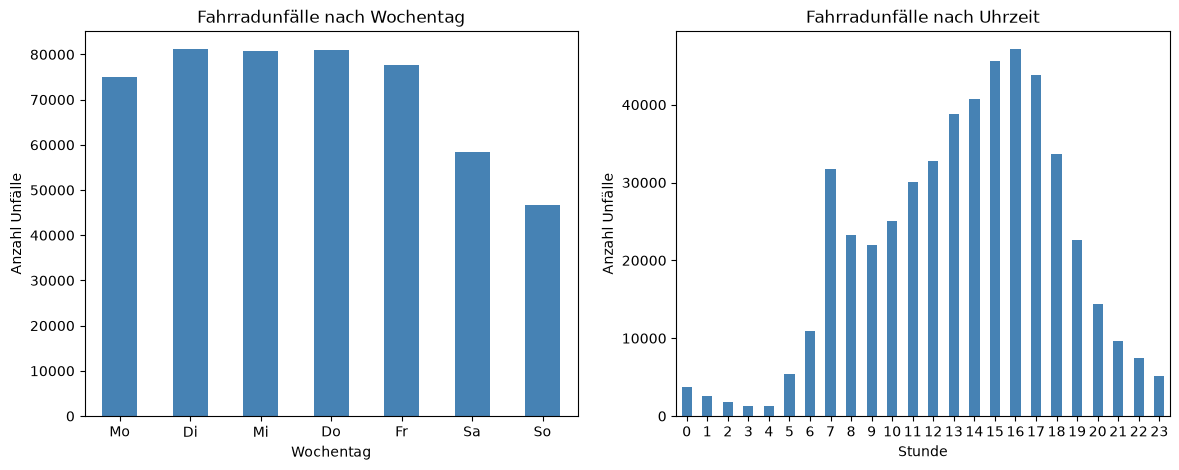

In [58]:
#  1.3 Entwicklung der Fahrradunfälle nach Wochentag und Tageszeit

tage = {2: "Mo", 3: "Di", 4: "Mi", 5: "Do", 6: "Fr", 7: "Sa", 1: "So"}
reihenfolge = [2, 3, 4, 5, 6, 7, 1]

# Wochentage
rad_tag = df_rad["UWOCHENTAG"].value_counts().reindex(reihenfolge)
rad_tag.index = [tage[i] for i in rad_tag.index]
print(rad_tag)

# Tageszeit
rad_stunde = df_rad["USTUNDE"].value_counts().sort_index()
print(rad_stunde.sort_values(ascending=False).head(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rad_tag.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Fahrradunfälle nach Wochentag")
axes[0].set_xlabel("Wochentag")
axes[0].set_ylabel("Anzahl Unfälle")
axes[0].tick_params(axis="x", rotation=0)

rad_stunde.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Fahrradunfälle nach Uhrzeit")
axes[1].set_xlabel("Stunde")
axes[1].set_ylabel("Anzahl Unfälle")
axes[1].tick_params(axis="x", rotation=0);

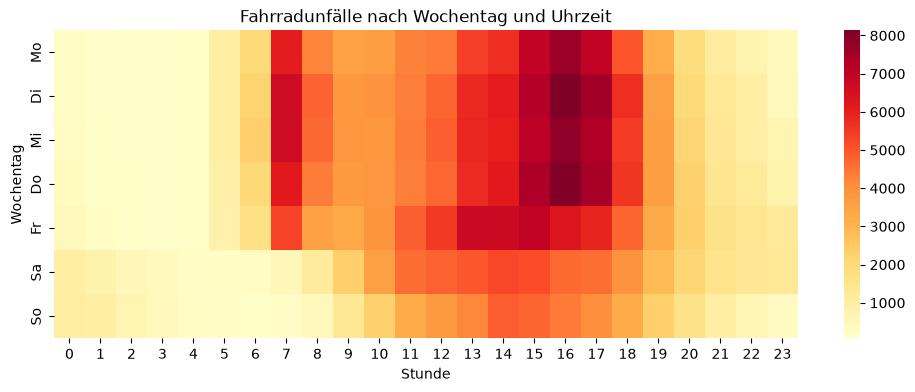

In [59]:
heat = (df_rad.pivot_table(index="UWOCHENTAG", columns="USTUNDE", values="IstRad", aggfunc="size")
              .reindex(reihenfolge))
heat.index = [tage[i] for i in heat.index]

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(heat, cmap="YlOrRd", ax=ax)
ax.set_title("Fahrradunfälle nach Wochentag und Uhrzeit")
ax.set_xlabel("Stunde")
ax.set_ylabel("Wochentag");

**Wochentage:** Fahrradunfälle passieren überwiegend werktags. Von Dienstag bis Donnerstag sind sie mit jeweils rund 81.000 Unfällen am häufigsten, am Montag (74.997) und Freitag (77.615) liegen sie etwas darunter. Am Wochenende sind es deutlich weniger: Samstag 58.520, Sonntag 46.759. Insgesamt passieren 395.520 Fahrradunfälle von Montag bis Freitag und 105.279 am Wochenende.

**Tageszeit:** Die meisten Fahrradunfälle ereignen sich am Nachmittag. Die Spitzenwerte liegen bei 16 Uhr (47.107), 15 Uhr (45.561) und 17 Uhr (43.846). Es gibt einen zweiten, kleineren Gipfel um 7 Uhr morgens (etwa 32.000), dazwischen ein Rückgang am Vormittag. In den Nachtstunden zwischen 1 und 4 Uhr passieren dagegen nur sehr wenige Unfälle.

**Kombination:** Die Heatmap zeigt zwei unterschiedliche Muster. Montag bis Donnerstag treten zwei Spitzen auf, morgens um 7 Uhr und am Nachmittag um 16 Uhr, was zu den üblichen Pendlerzeiten passt. Am Freitag verlagert sich die Häufung auf den frühen bis mittleren Nachmittag (etwa 13 bis 16 Uhr), die Morgenspitze ist schwächer. Am Wochenende fehlt die Morgenspitze, die Unfälle verteilen sich über den Tag mit einem Schwerpunkt am Nachmittag.

2. Räumliche Verteilung

                        Gesamt  Anteil (%)
Bundesland                                
Nordrhein-Westfalen     109796       21.92
Bayern                   95069       18.98
Baden-Württemberg        58337       11.65
Niedersachsen            48631        9.71
Berlin                   27751        5.54
Schleswig-Holstein       26068        5.21
Sachsen                  25631        5.12
Hessen                   23114        4.62
Brandenburg              16927        3.38
Hamburg                  16655        3.33
Rheinland-Pfalz          15498        3.09
Sachsen-Anhalt           12015        2.40
Mecklenburg-Vorpommern    8906        1.78
Thüringen                 7205        1.44
Bremen                    6081        1.21
Saarland                  3115        0.62


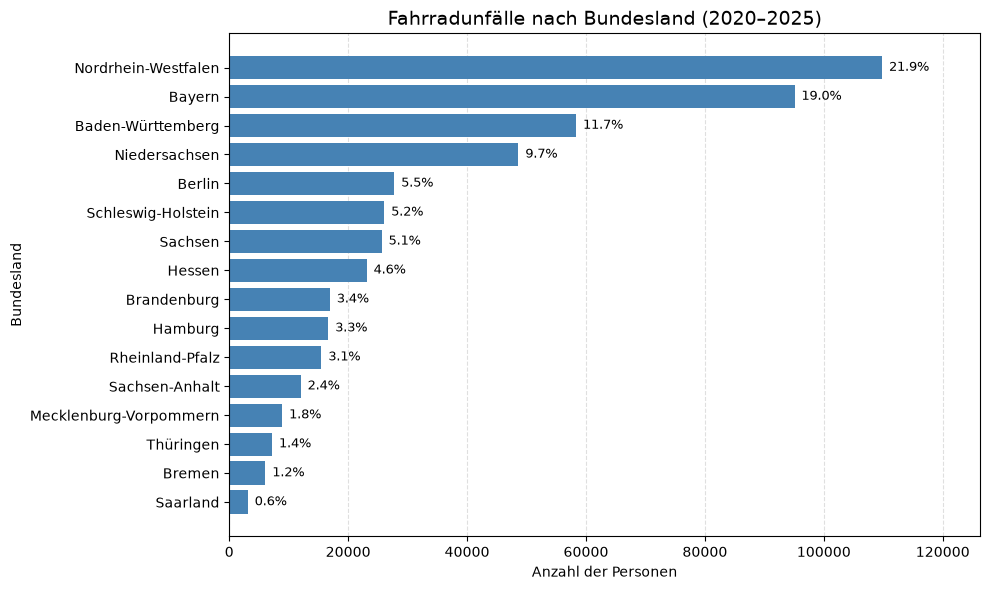

In [61]:
# 2.1.1 Fahrradunfälle nach Bundesland

laender = {
    1: "Schleswig-Holstein",
    2: "Hamburg",
    3: "Niedersachsen",
    4: "Bremen",
    5: "Nordrhein-Westfalen",
    6: "Hessen",
    7: "Rheinland-Pfalz",
    8: "Baden-Württemberg",
    9: "Bayern",
    10: "Saarland",
    11: "Berlin",
    12: "Brandenburg",
    13: "Mecklenburg-Vorpommern",
    14: "Sachsen",
    15: "Sachsen-Anhalt",
    16: "Thüringen",
}

df_rad["Bundesland"] = df_rad["ULAND"].map(laender)

land_gesamt = (df_rad["Bundesland"].value_counts().to_frame(name="Gesamt"))

# Prozentualer Anteil am Gesamtwert Deutschlands
land_gesamt["Anteil (%)"] = (land_gesamt["Gesamt"] / land_gesamt["Gesamt"].sum()* 100).round(2)
print(land_gesamt)

# Balkendiagramm
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(land_gesamt.index, land_gesamt["Gesamt"], color="steelblue")

# Prozentangaben rechts neben den Balken
for bar, prozent in zip(bars, land_gesamt["Anteil (%)"]):
    ax.annotate(
        f"{prozent:.1f}%",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Fahrradunfälle nach Bundesland (2020–2025)",
    fontsize=14
)
ax.set_xlabel("Anzahl der Personen")
ax.set_ylabel("Bundesland")
ax.invert_yaxis()
ax.set_xlim(0, land_gesamt["Gesamt"].max() * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout();

401 True [5]
ars
01001     Flensburg (Kreisfreie Stadt)
01002          Kiel (Kreisfreie Stadt)
01003        Lübeck (Kreisfreie Stadt)
01004    Neumünster (Kreisfreie Stadt)
01051             Dithmarschen (Kreis)
dtype: str
Nicht zugeordnete Datensätze: 63 von 500799
Anteil an allen Datensätzen: 0.0126 %

Nicht zugeordnete Gebietsschlüssel:
ULAND  UREGBEZ  UKREIS  kreis_key
16     0        56      16056        63
Landkreis
Berlin (Kreisfreie Stadt)               27751
Hamburg (Kreisfreie Stadt)              16655
München (Kreisfreie Stadt)              14244
Köln (Kreisfreie Stadt)                 11108
Region Hannover (Landkreis)             10700
Dresden (Kreisfreie Stadt)               7000
Leipzig (Kreisfreie Stadt)               5531
Bremen (Kreisfreie Stadt)                5132
Düsseldorf (Kreisfreie Stadt)            4887
Frankfurt am Main (Kreisfreie Stadt)     4812
Nürnberg (Kreisfreie Stadt)              4387
Münster (Kreisfreie Stadt)               4364
Steinfurt (Kreis)     

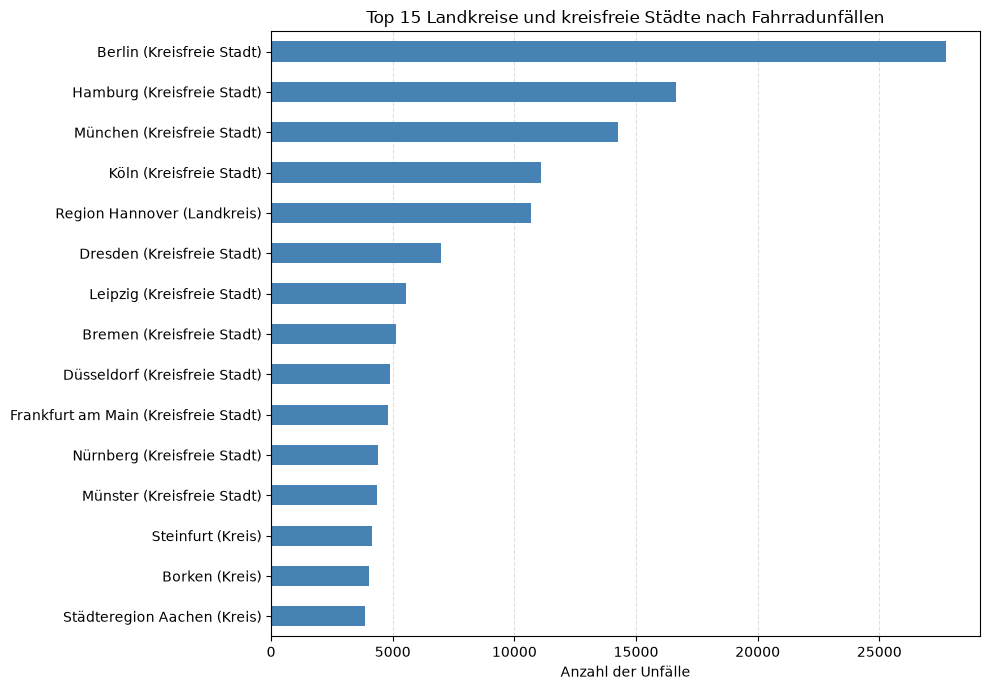

In [74]:
# 2.1.2 Fahrradunfälle nach Landkreis

# Verzeichnis einlesen
pfad = "data/20260131_Anschriften_der_Gemeinde_und_Stadtverwaltungen.xlsx"

raw = pd.read_excel(
    pfad,
    sheet_name="Anschriften_31_01_2026",
    header=None,
    dtype=str
)

gv = raw.iloc[6:, [2, 4, 5, 6, 7]].copy()
gv.columns = ["satzart", "art", "ars", "ags", "name"]


# Satzart 40 = Landkreise und kreisfreie Städte
kreise = gv[gv["satzart"] == "40"]

# Kontrolle
print(len(kreise), kreise["ars"].is_unique, kreise["ars"].str.len().unique())


# Schlüssel -> Name, z. B. "München (Kreisfreie Stadt)"
kreis_namen = (kreise["name"].str.split(",").str[0] + " (" + kreise["art"] + ")").set_axis(kreise["ars"])
print(kreis_namen.head())

# Schlüssel in den Unfalldaten
df_rad["kreis_key"] = (
    df_rad["ULAND"].astype(str).str.zfill(2)
    + df_rad["UREGBEZ"].astype(str)
    + df_rad["UKREIS"].astype(str).str.zfill(2)
)

# Berlin und Hamburg sind in den Unfalldaten in Bezirke unterteilt -> eine Stadt
df_rad["kreis_key"] = df_rad["kreis_key"].mask(df_rad["ULAND"] == 11, "11000")
df_rad["kreis_key"] = df_rad["kreis_key"].mask(df_rad["ULAND"] == 2, "02000")

df_rad["Landkreis"] = df_rad["kreis_key"].map(kreis_namen)

# Kontrolle der Zuordnung 
nicht_gefunden = df_rad["Landkreis"].isna()

print("Nicht zugeordnete Datensätze:", nicht_gefunden.sum(), "von", len(df_rad))
print("Anteil an allen Datensätzen:", round(nicht_gefunden.mean() * 100, 4), "%")
print("\nNicht zugeordnete Gebietsschlüssel:")
print(
    df_rad.loc[nicht_gefunden, ["ULAND", "UREGBEZ", "UKREIS", "kreis_key"]]
    .value_counts()
    .to_string()
)

# Diagramm
top_kreise = df_rad["Landkreis"].value_counts().head(15)
print(top_kreise)

fig, ax = plt.subplots(figsize=(10, 7))
top_kreise.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Top 15 Landkreise und kreisfreie Städte nach Fahrradunfällen")
ax.set_xlabel("Anzahl der Unfälle")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout();


Bei der Zuordnung der Unfalldaten zu den Landkreisen und kreisfreien Städten 
konnten 63 von insgesamt 500.799 Datensätzen (ca. 0,013 %) nicht zugeordnet werden. 
Alle 63 Datensätze weisen den Gebietsschlüssel 16056 auf, der im verwendeten 
Verwaltungsverzeichnis vom Januar 2026 nicht enthalten ist. Dies hängt vermutlich 
mit einer Änderung der Verwaltungsstruktur zusammen. Da der Anteil der nicht 
zugeordneten Datensätze sehr gering ist, wurden sie für die Auswertung nach 
Landkreisen nicht berücksichtigt.

10749 0 [8] True
Gemeinde nicht gefunden: 618 von 500799
Anteil: 0.123 %
gemeinde_key
06435014    464
16056000     63
03153007     13
03153504     13
16064055      6
Name: count, dtype: int64
Berlin                  27751
Hamburg                 16655
München                 14244
Köln                    11108
Dresden                  7000
Hannover                 6618
Leipzig                  5531
Bremen                   5132
Düsseldorf               4887
Frankfurt am Main        4812
Nürnberg                 4387
Münster                  4364
Freiburg im Breisgau     3563
Augsburg                 3443
Bonn                     3355
Name: count, dtype: int64


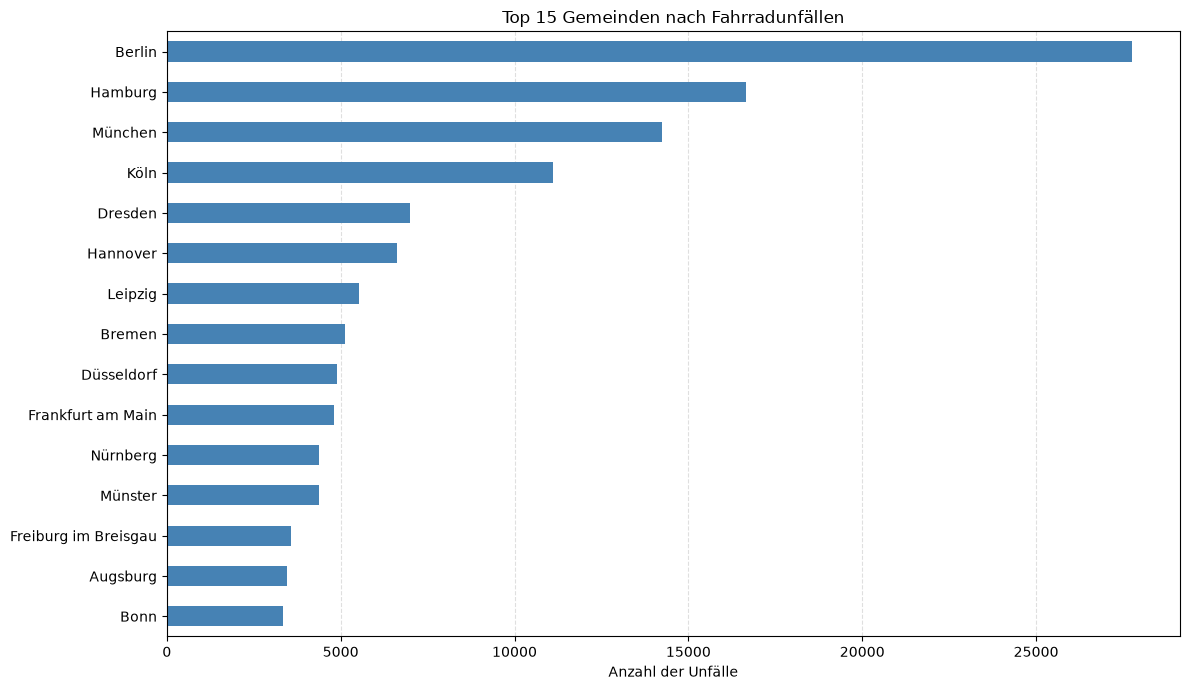

In [77]:
# 2.1.3 Fahrradunfälle nach Gemeinden

# Gemeinden aus dem Verzeichnis (Satzart 60), Doppelzeilen entfernen
gemeinden = gv[gv["satzart"] == "60"].drop_duplicates(subset="ags")

# Kontrolle: keine leeren Schlüssel, alle 8-stellig, eindeutig
print(len(gemeinden), gemeinden["ags"].isna().sum(), gemeinden["ags"].str.len().unique(), gemeinden["ags"].is_unique)


# Schlüssel -> Name (nur der Teil vor dem Komma)
gemeinde_namen = gemeinden.set_index("ags")["name"].str.split(",").str[0]

# Schlüssel in den Unfalldaten
df_rad["gemeinde_key"] = df_rad["kreis_key"] + df_rad["UGEMEINDE"].astype(str).str.zfill(3)

# Berlin und Hamburg: in den Unfalldaten in Bezirke unterteilt -> eine Gemeinde
df_rad.loc[df_rad["ULAND"] == 11, "gemeinde_key"] = "11000000"
df_rad.loc[df_rad["ULAND"] == 2, "gemeinde_key"] = "02000000"

df_rad["Gemeinde"] = df_rad["gemeinde_key"].map(gemeinde_namen)

# Kontrolle der Zuordnung 
nicht_gefunden = df_rad["Gemeinde"].isna()
print("Gemeinde nicht gefunden:", nicht_gefunden.sum(), "von", len(df_rad))
print("Anteil:", round(nicht_gefunden.mean() * 100, 3), "%")
print(df_rad.loc[nicht_gefunden, "gemeinde_key"].value_counts().head())

# Top 15 nach Schlüssel zählen (gleichnamige Gemeinden bleiben getrennt)
top_gemeinden = df_rad["gemeinde_key"].value_counts().head(15)
top_gemeinden.index = [gemeinde_namen.get(k, k) for k in top_gemeinden.index]
print(top_gemeinden)

fig, ax = plt.subplots(figsize=(12, 7))
top_gemeinden.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Top 15 Gemeinden nach Fahrradunfällen")
ax.set_xlabel("Anzahl der Unfälle")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout();


Zuordnung der Gemeinden

Die Zuordnung der Gemeinden erfolgte anhand des Gemeindeschlüssels, 
der aus dem Kreisschlüssel (kreis_key) und dem Gemeindecode (UGEMEINDE) gebildet wurde.
Die Zuordnung der Gemeindenamen erfolgte mithilfe des Verwaltungsverzeichnisses.
Von insgesamt 500.799 Unfallmeldungen konnten 500.181 (99,877 %) einer Gemeinde 
zugeordnet werden. Bei 618 Unfallmeldungen (0,123 %) war keine eindeutige Zuordnung
möglich. Diese Datensätze wurden keiner Gemeinde zugewiesen, 
um fehlerhafte Zuordnungen zu vermeiden.